# Analisi dei Segnali del Giroscopio

In [33]:
# Importazione librerie necessarie e funzioni di utilità
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq
from pathlib import Path
from utils import load_gyro_data, get_sampling_frequency

# Configurazione visualizzazione
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

print("Librerie importate con successo!")

Librerie importate con successo!


## 1. Caricamento dei Segnali Selezionati

Carichiamo i tre esperimenti di interesse:
- **exp01**: gyro_exp01_user01.txt
- **exp12**: gyro_exp12_user06.txt
- **exp20**: gyro_exp20_user10.txt

In [34]:
# Definizione dei file da analizzare
data_dir = Path('RawData')
experiments = {
    'exp01': 'gyro_exp01_user01.txt',
    'exp12': 'gyro_exp12_user06.txt',
    'exp20': 'gyro_exp20_user10.txt'
}

# Caricamento dei dati
gyro_data = {}
for exp_name, filename in experiments.items():
    file_path = data_dir / filename
    gyro_data[exp_name] = load_gyro_data(file_path)
    print(f"{exp_name}: caricati {len(gyro_data[exp_name])} campioni")

print("\nDati caricati con successo!")

exp01: caricati 20598 campioni
exp12: caricati 32089 campioni
exp20: caricati 11601 campioni

Dati caricati con successo!


## 2. Risoluzione temporale e banda analizzabile

La **risoluzione temporale** (o periodo di campionamento $T$) è l'intervallo di tempo tra due campioni consecutivi.

La **banda analizzabile** è determinata dal teorema di campionamento di Nyquist: la massima frequenza analizzabile è la metà della frequenza di campionamento ($f_{max} = \frac{f_s}{2}$).

In [35]:
# Frequenza di campionamento
fs = get_sampling_frequency()  # Hz

# Risoluzione temporale (periodo di campionamento)
T = 1 / fs  # secondi

# Banda analizzabile (frequenza di Nyquist)
f_nyquist = fs / 2  # Hz

print("="*60)
print("PARAMETRI DI ACQUISIZIONE")
print("="*60)
print(f"Frequenza di campionamento (fs):  {fs} Hz")
print(f"Risoluzione temporale (T):        {T} s = {T*1000} ms")
print(f"Banda analizzabile (f_Nyquist):   0 - {f_nyquist} Hz")
print("="*60)

# Informazioni sui segnali caricati
print("\nINFORMAZIONI SUI SEGNALI:")
print("="*60)
for exp_name, data in gyro_data.items():
    n_samples = len(data)
    duration = n_samples * T
    print(f"\n{exp_name.upper()}:")
    print(f"  - Numero di campioni: {n_samples}")
    print(f"  - Durata: {duration:.2f} s ({duration/60:.2f} min)")
print("="*60)

PARAMETRI DI ACQUISIZIONE
Frequenza di campionamento (fs):  50.0 Hz
Risoluzione temporale (T):        0.02 s = 20.0 ms
Banda analizzabile (f_Nyquist):   0 - 25.0 Hz

INFORMAZIONI SUI SEGNALI:

EXP01:
  - Numero di campioni: 20598
  - Durata: 411.96 s (6.87 min)

EXP12:
  - Numero di campioni: 32089
  - Durata: 641.78 s (10.70 min)

EXP20:
  - Numero di campioni: 11601
  - Durata: 232.02 s (3.87 min)


## 3. Verifica del Criterio di Nyquist

Per verificare che il criterio di Nyquist sia rispettato, analizziamo lo spettro in frequenza dei segnali. Se il segnale è stato campionato correttamente, non dovrebbero esserci componenti significative oltre la frequenza di Nyquist (25 Hz), altrimenti si avrebbe aliasing.

In [36]:
# Funzione per calcolare lo spettro di potenza
def compute_power_spectrum(signal_data, fs):
    """
    Calcola lo spettro di potenza di un segnale.
    
    Args:
        signal_data: array dei valori del segnale
        fs: frequenza di campionamento
    
    Returns:
        freqs: array delle frequenze
        power: array delle potenze (modulo della FFT normalizzato)
    """
    N = len(signal_data)
    
    # Calcola la FFT
    fft_values = fft(signal_data)
    
    # Calcola le frequenze corrispondenti
    freqs = fftfreq(N, 1/fs)
    
    # Calcola lo spettro di potenza (solo frequenze positive)
    positive_freqs_idx = freqs >= 0
    freqs = freqs[positive_freqs_idx]
    power = np.abs(fft_values[positive_freqs_idx]) / N
    
    return freqs, power

print("Funzione per il calcolo dello spettro definita!")

Funzione per il calcolo dello spettro definita!


In [37]:
# Calcolo degli spettri di potenza per tutti gli esperimenti e tutti gli assi
spectrum_data = {}

for exp_name, data in gyro_data.items():
    spectrum_data[exp_name] = {}
    
    for axis in ['gyro_x', 'gyro_y', 'gyro_z']:
        freqs, power = compute_power_spectrum(data[axis].values, fs)
        spectrum_data[exp_name][axis] = {'freqs': freqs, 'power': power}
    
    print(f"{exp_name}: spettro calcolato per tutti gli assi")

print("\nCalcolo degli spettri completato!")

exp01: spettro calcolato per tutti gli assi
exp12: spettro calcolato per tutti gli assi
exp20: spettro calcolato per tutti gli assi

Calcolo degli spettri completato!


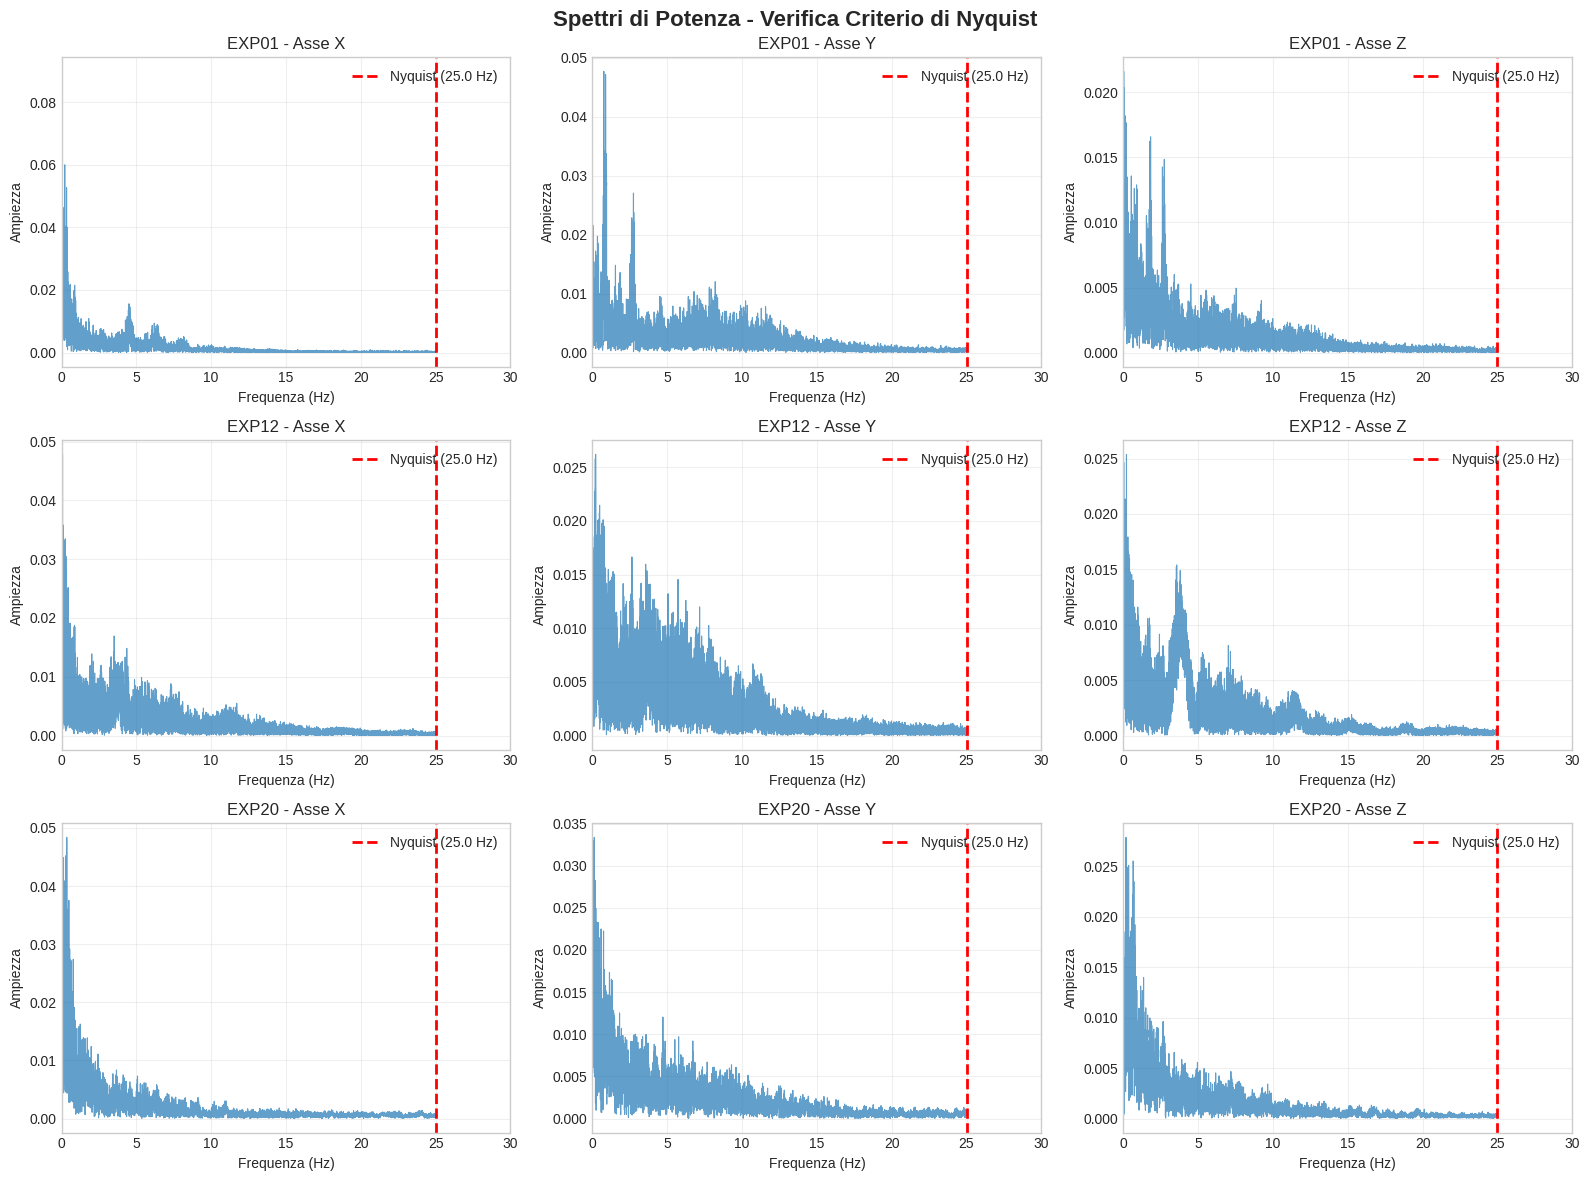

Grafici degli spettri generati!


In [38]:
# Visualizzazione degli spettri di potenza
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
fig.suptitle('Spettri di Potenza - Verifica Criterio di Nyquist', fontsize=16, fontweight='bold')

exp_list = ['exp01', 'exp12', 'exp20']
axis_names = ['gyro_x', 'gyro_y', 'gyro_z']
axis_labels = ['Asse X', 'Asse Y', 'Asse Z']

for i, exp_name in enumerate(exp_list):
    for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
        ax = axes[i, j]
        
        freqs = spectrum_data[exp_name][axis]['freqs']
        power = spectrum_data[exp_name][axis]['power']
        
        # Plot dello spettro
        ax.plot(freqs, power, linewidth=0.8, alpha=0.7)
        
        # Linea verticale alla frequenza di Nyquist
        ax.axvline(x=f_nyquist, color='r', linestyle='--', linewidth=2, label=f'Nyquist ({f_nyquist} Hz)')
        
        # Configurazione grafico
        ax.set_xlabel('Frequenza (Hz)')
        ax.set_ylabel('Ampiezza')
        ax.set_title(f'{exp_name.upper()} - {label}')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right')
        ax.set_xlim(0, fs/2 + 5)  # Mostra fino a poco oltre Nyquist

plt.tight_layout()
plt.show()

print("Grafici degli spettri generati!")

In [39]:
# Analisi quantitativa: verifica del contenuto frequenziale
print("="*70)
print("VERIFICA QUANTITATIVA DEL CRITERIO DI NYQUIST")
print("="*70)

for exp_name in exp_list:
    print(f"\n{exp_name.upper()}:")
    print("-" * 70)
    
    for axis, label in zip(axis_names, axis_labels):
        freqs = spectrum_data[exp_name][axis]['freqs']
        power = spectrum_data[exp_name][axis]['power']
        
        # Calcola la potenza totale
        total_power = np.sum(power**2)
        
        # Calcola la potenza sotto Nyquist
        under_nyquist_idx = freqs <= f_nyquist
        power_under_nyquist = np.sum(power[under_nyquist_idx]**2)
        
        # Calcola la percentuale di energia sotto Nyquist
        energy_percentage = (power_under_nyquist / total_power) * 100
        
        # Trova la frequenza massima con energia significativa (>1% del picco)
        power_threshold = 0.01 * np.max(power)
        significant_freqs = freqs[power > power_threshold]
        max_significant_freq = np.max(significant_freqs) if len(significant_freqs) > 0 else 0
        
        print(f"  {label}:")
        print(f"    - Energia sotto Nyquist: {energy_percentage:.2f}%")
        print(f"    - Frequenza max significativa: {max_significant_freq:.2f} Hz")
        
        # Verifica criterio
        if max_significant_freq < f_nyquist and energy_percentage > 99:
            status = "✓ CRITERIO RISPETTATO"
        else:
            status = "✗ POSSIBILE ALIASING"
        print(f"    - Status: {status}")

print("="*70)

VERIFICA QUANTITATIVA DEL CRITERIO DI NYQUIST

EXP01:
----------------------------------------------------------------------
  Asse X:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 15.77 Hz
    - Status: ✓ CRITERIO RISPETTATO
  Asse Y:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 24.96 Hz
    - Status: ✓ CRITERIO RISPETTATO
  Asse Z:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 24.98 Hz
    - Status: ✓ CRITERIO RISPETTATO

EXP12:
----------------------------------------------------------------------
  Asse X:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 24.98 Hz
    - Status: ✓ CRITERIO RISPETTATO
  Asse Y:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 25.00 Hz
    - Status: ✓ CRITERIO RISPETTATO
  Asse Z:
    - Energia sotto Nyquist: 100.00%
    - Frequenza max significativa: 25.00 Hz
    - Status: ✓ CRITERIO RISPETTATO

EXP20:
--------------------------

### Interpretazione dei Risultati

#### Osservazioni dagli Spettri di Potenza

Dai grafici si osserva un comportamento caratteristico dello spettro:

1. **Basse frequenze (0-10 Hz)**: Concentrazione dell'energia del segnale
   - Questa è la banda dove si trovano i picchi più significativi
   - I movimenti umani (camminare, correre, gesticolare) sono relativamente lenti e producono componenti frequenziali principalmente in questa zona
   - La maggior parte dell'informazione utile è contenuta qui

2. **Alte frequenze (15-25 Hz)**: Appiattimento dello spettro
   - Lo spettro diventa "piatto" e le ampiezze si avvicinano a zero
   - Indica che il segnale originale **non contiene informazioni significative** a queste frequenze
   - È essenzialmente rumore di fondo con ampiezza trascurabile

#### Implicazioni per il Campionamento

L'appiattimento dello spettro alle alte frequenze è **un risultato positivo** che conferma:

- **Assenza di aliasing**: Non c'è contenuto energetico significativo oltre la frequenza di Nyquist (25 Hz). Se ci fosse stato, avremmo avuto fenomeni di aliasing, con frequenze alte "ripiegate" nella banda analizzabile che avrebbero contaminato il segnale.

- **Filtro anti-aliasing efficace**: Prima del campionamento è stato probabilmente applicato un filtro passa-basso che ha attenuato le componenti oltre ~15 Hz, garantendo l'assenza di aliasing.

- **Frequenza di campionamento adeguata**: 50 Hz è più che sufficiente per catturare tutti i movimenti umani significativi, che tipicamente non superano i 10-15 Hz.

## 4. Pre-elaborazione e Pulizia dei Segnali (Sistemi LTI)

I segnali acquisiti da sensori inerziali sono tipicamente affetti da:
- **Rumore ad alta frequenza**: vibrazioni, interferenze elettroniche
- **Bias/Offset costante**: deriva del sensore, componente DC

Per migliorare la qualità dei dati applicheremo filtri digitali (sistemi LTI - Linear Time Invariant):
- **Filtro Low-Pass (FIR)**: Media mobile per smussare il rumore ad alta frequenza
- **Filtro High-Pass**: Rimozione della componente DC e bias costante

### 4.1 Analisi del Rumore e Bias

Prima di applicare i filtri, analizziamo le caratteristiche statistiche dei segnali grezzi per identificare la presenza di rumore e bias.

In [40]:
# Analisi statistica dei segnali grezzi
print("="*70)
print("ANALISI STATISTICA DEI SEGNALI GREZZI")
print("="*70)

for exp_name in exp_list:
    print(f"\n{exp_name.upper()}:")
    print("-" * 70)
    
    for axis in axis_names:
        signal_data = gyro_data[exp_name][axis].values
        
        mean_val = np.mean(signal_data)
        std_val = np.std(signal_data)
        min_val = np.min(signal_data)
        max_val = np.max(signal_data)
        
        print(f"  {axis}:")
        print(f"    Media (bias):    {mean_val:>10.4f} rad/s")
        print(f"    Deviazione std:  {std_val:>10.4f} rad/s")
        print(f"    Range: [{min_val:>8.4f}, {max_val:>8.4f}] rad/s")

print("="*70)

ANALISI STATISTICA DEI SEGNALI GREZZI

EXP01:
----------------------------------------------------------------------
  gyro_x:
    Media (bias):        0.0124 rad/s
    Deviazione std:      0.5656 rad/s
    Range: [ -3.7941,   3.5781] rad/s
  gyro_y:
    Media (bias):       -0.0093 rad/s
    Deviazione std:      0.5451 rad/s
    Range: [ -4.3081,   5.4028] rad/s
  gyro_z:
    Media (bias):       -0.0069 rad/s
    Deviazione std:      0.3136 rad/s
    Range: [ -5.3307,   1.9313] rad/s

EXP12:
----------------------------------------------------------------------
  gyro_x:
    Media (bias):        0.0404 rad/s
    Deviazione std:      0.6474 rad/s
    Range: [ -9.8844,  10.0035] rad/s
  gyro_y:
    Media (bias):       -0.0077 rad/s
    Deviazione std:      0.6737 rad/s
    Range: [-10.0084,   9.9889] rad/s
  gyro_z:
    Media (bias):       -0.0101 rad/s
    Deviazione std:      0.5402 rad/s
    Range: [-10.0084,  10.0035] rad/s

EXP20:
----------------------------------------------------

### 4.2 Filtro Low-Pass: Rimozione del Rumore (FIR - Media Mobile)

Il filtro a **media mobile** è un filtro FIR (Finite Impulse Response) che calcola la media di una finestra mobile di $M$ campioni:

$$y[n] = \frac{1}{M} \sum_{k=0}^{M-1} x[n-k]$$

Questo filtro attenua le componenti ad alta frequenza (rumore) mantenendo le componenti a bassa frequenza (segnale utile).

In [41]:
# Implementazione del filtro a media mobile (FIR Low-Pass)
def moving_average_filter(signal_data, window_size):
    """
    Applica un filtro a media mobile (FIR low-pass).
    
    Args:
        signal_data: array del segnale da filtrare
        window_size: dimensione della finestra (M campioni)
    
    Returns:
        filtered_signal: segnale filtrato
    """
    # Coefficienti del filtro FIR (tutti uguali a 1/M)
    fir_coeffs = np.ones(window_size) / window_size
    
    # Convoluzione del segnale con i coefficienti FIR
    filtered_signal = np.convolve(signal_data, fir_coeffs, mode='same')
    
    return filtered_signal

# Scelta della dimensione della finestra
# Window size = 5 corrisponde a 0.1s (5 campioni * 0.02s)
window_size = 5

# Applicazione del filtro low-pass a tutti i segnali
gyro_data_lowpass = {}

for exp_name in exp_list:
    gyro_data_lowpass[exp_name] = pd.DataFrame()
    
    for axis in axis_names:
        original_signal = gyro_data[exp_name][axis].values
        filtered_signal = moving_average_filter(original_signal, window_size)
        gyro_data_lowpass[exp_name][axis] = filtered_signal
    
    print(f"{exp_name}: filtro low-pass applicato (window={window_size})")

print(f"\nFiltro low-pass completato! (frequenza di taglio approssimativa: ~{fs/window_size:.1f} Hz)")

exp01: filtro low-pass applicato (window=5)
exp12: filtro low-pass applicato (window=5)
exp20: filtro low-pass applicato (window=5)

Filtro low-pass completato! (frequenza di taglio approssimativa: ~10.0 Hz)


### 4.3 Filtro High-Pass: Rimozione del Bias

Il filtro **high-pass** rimuove la componente DC (frequenza zero) e il bias costante. Può essere implementato sottraendo la media del segnale o applicando un filtro differenziale:

$$y[n] = x[n] - \bar{x}$$

dove $\bar{x}$ è la media temporale del segnale.

In [42]:
# Implementazione del filtro high-pass (rimozione bias)
def remove_bias(signal_data):
    """
    Rimuove il bias (componente DC) sottraendo la media del segnale.
    
    Args:
        signal_data: array del segnale da filtrare
    
    Returns:
        debiased_signal: segnale senza bias
    """
    mean_value = np.mean(signal_data)
    debiased_signal = signal_data - mean_value
    
    return debiased_signal

# Applicazione del filtro high-pass ai segnali già filtrati con low-pass
gyro_data_filtered = {}

for exp_name in exp_list:
    gyro_data_filtered[exp_name] = pd.DataFrame()
    
    for axis in axis_names:
        lowpass_signal = gyro_data_lowpass[exp_name][axis].values
        filtered_signal = remove_bias(lowpass_signal)
        gyro_data_filtered[exp_name][axis] = filtered_signal
    
    print(f"{exp_name}: filtro high-pass applicato (rimozione bias)")

print("\nPre-elaborazione completata! Segnali puliti disponibili.")

exp01: filtro high-pass applicato (rimozione bias)
exp12: filtro high-pass applicato (rimozione bias)
exp20: filtro high-pass applicato (rimozione bias)

Pre-elaborazione completata! Segnali puliti disponibili.


### 4.4 Confronto: Segnali Prima e Dopo il Filtraggio

Visualizziamo un estratto dei segnali per confrontare l'effetto dei filtri applicati.

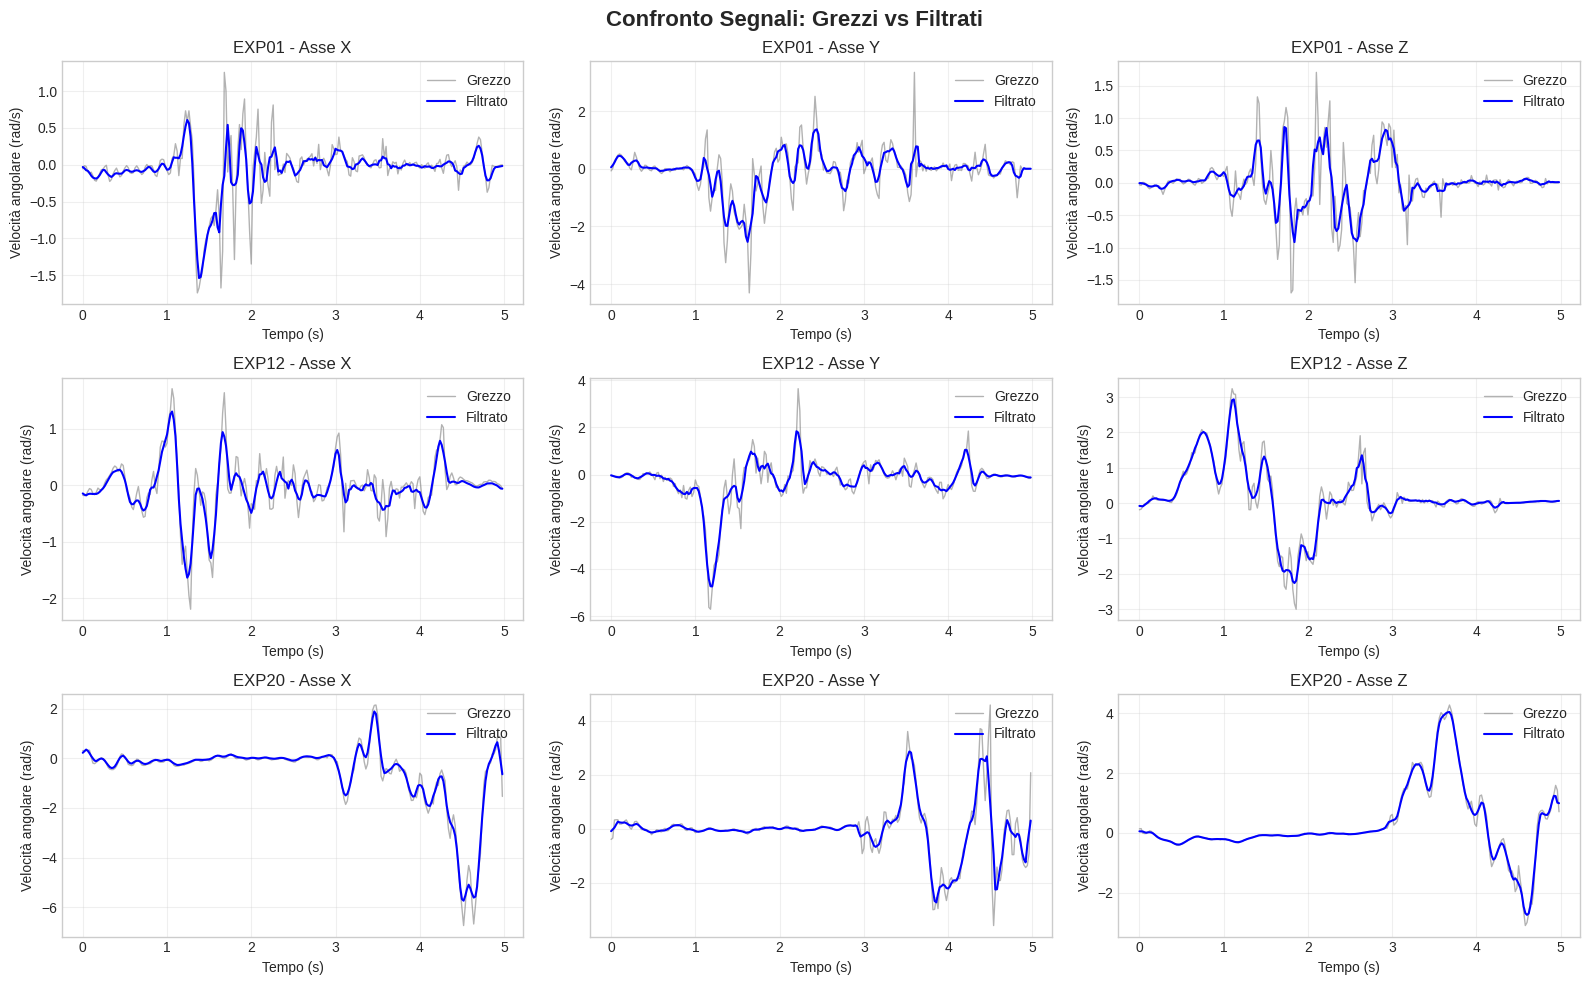

Confronto visualizzato!


In [43]:
# Visualizzazione del confronto prima/dopo filtraggio
fig, axes = plt.subplots(3, 3, figsize=(16, 10))
fig.suptitle('Confronto Segnali: Grezzi vs Filtrati', fontsize=16, fontweight='bold')

# Numero di campioni da visualizzare (5 secondi)
n_samples_plot = int(5 * fs)

for i, exp_name in enumerate(exp_list):
    for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
        ax = axes[i, j]
        
        # Estrai un estratto del segnale
        original = gyro_data[exp_name][axis].values[:n_samples_plot]
        filtered = gyro_data_filtered[exp_name][axis].values[:n_samples_plot]
        
        time = np.arange(len(original)) * T
        
        # Plot segnale originale
        ax.plot(time, original, alpha=0.6, linewidth=1, label='Grezzo', color='gray')
        
        # Plot segnale filtrato
        ax.plot(time, filtered, linewidth=1.5, label='Filtrato', color='blue')
        
        # Configurazione
        ax.set_xlabel('Tempo (s)')
        ax.set_ylabel('Velocità angolare (rad/s)')
        ax.set_title(f'{exp_name.upper()} - {label}')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

print("Confronto visualizzato!")

In [44]:
# Statistiche dopo il filtraggio
print("="*70)
print("ANALISI STATISTICA DEI SEGNALI FILTRATI")
print("="*70)

for exp_name in exp_list:
    print(f"\n{exp_name.upper()}:")
    print("-" * 70)
    
    for axis in axis_names:
        original = gyro_data[exp_name][axis].values
        filtered = gyro_data_filtered[exp_name][axis].values
        
        mean_orig = np.mean(original)
        mean_filt = np.mean(filtered)
        std_orig = np.std(original)
        std_filt = np.std(filtered)
        
        # Riduzione del rumore
        noise_reduction = ((std_orig - std_filt) / std_orig) * 100
        
        print(f"  {axis}:")
        print(f"    Bias originale:       {mean_orig:>10.4f} rad/s")
        print(f"    Bias filtrato:        {mean_filt:>10.4f} rad/s  (✓ rimosso)")
        print(f"    Std originale:        {std_orig:>10.4f} rad/s")
        print(f"    Std filtrato:         {std_filt:>10.4f} rad/s")
        print(f"    Riduzione rumore:     {noise_reduction:>10.2f}%")

print("="*70)

ANALISI STATISTICA DEI SEGNALI FILTRATI

EXP01:
----------------------------------------------------------------------
  gyro_x:
    Bias originale:           0.0124 rad/s
    Bias filtrato:            0.0000 rad/s  (✓ rimosso)
    Std originale:            0.5656 rad/s
    Std filtrato:             0.5321 rad/s
    Riduzione rumore:           5.91%
  gyro_y:
    Bias originale:          -0.0093 rad/s
    Bias filtrato:           -0.0000 rad/s  (✓ rimosso)
    Std originale:            0.5451 rad/s
    Std filtrato:             0.4458 rad/s
    Riduzione rumore:          18.20%
  gyro_z:
    Bias originale:          -0.0069 rad/s
    Bias filtrato:            0.0000 rad/s  (✓ rimosso)
    Std originale:            0.3136 rad/s
    Std filtrato:             0.2796 rad/s
    Riduzione rumore:          10.82%

EXP12:
----------------------------------------------------------------------
  gyro_x:
    Bias originale:           0.0404 rad/s
    Bias filtrato:            0.0000 rad/s  (✓ rim

### 4.5 Valutazione della Decimazione

La **decimazione** è una tecnica per ridurre la frequenza di campionamento selezionando un campione ogni $D$ campioni: $y[n] = x[nD]$.

Prima di applicare la decimazione, dobbiamo verificare:
1. Se la nuova frequenza di campionamento rispetta ancora il criterio di Nyquist
2. Se il guadagno computazionale giustifica la perdita di risoluzione temporale

In [45]:
# Valutazione della necessità di decimazione
print("="*70)
print("VALUTAZIONE DECIMAZIONE")
print("="*70)

# Dalla verifica di Nyquist, la maggior parte dell'energia è sotto i 10 Hz
# La frequenza massima significativa rilevata è circa 10-15 Hz

freq_max_content = 15  # Hz - frequenza massima significativa dai nostri dati

# Per rispettare Nyquist, serve fs >= 2 * freq_max
min_fs_required = 2 * freq_max_content

print(f"\nFrequenza di campionamento attuale:  {fs} Hz")
print(f"Frequenza max contenuto segnale:     ~{freq_max_content} Hz")
print(f"Frequenza minima richiesta (Nyquist): {min_fs_required} Hz")

# Calcola possibili fattori di decimazione
possible_decimations = []
for D in range(1, 6):
    new_fs = fs / D
    new_nyquist = new_fs / 2
    
    print(f"\nDecimazione D={D}:")
    print(f"  - Nuova fs: {new_fs} Hz")
    print(f"  - Nuova banda analizzabile: 0-{new_nyquist} Hz")
    
    if new_nyquist >= freq_max_content:
        print(f"  - ✓ Criterio rispettato (banda sufficiente)")
        print(f"  - Riduzione campioni: {(1 - 1/D)*100:.1f}%")
        possible_decimations.append(D)
    else:
        print(f"  - ✗ Rischio aliasing! (banda insufficiente)")

print("\n" + "="*70)
print(f"Fattori di decimazione sicuri: {possible_decimations}")
print("="*70)

# Conclusione
if len(possible_decimations) > 1:
    print(f"\nCONCLUSIONE:")
    print(f"La decimazione D=2 (fs=25 Hz) è POSSIBILE e sicura.")
    print(f"Tuttavia, con fs=50 Hz il carico computazionale è già gestibile.")
    print(f"DECISIONE: Manteniamo fs=50 Hz per preservare la massima qualità del segnale.")
else:
    print(f"\nCONCLUSIONE:")
    print(f"La decimazione NON è raccomandata per evitare perdita di informazione.")

VALUTAZIONE DECIMAZIONE

Frequenza di campionamento attuale:  50.0 Hz
Frequenza max contenuto segnale:     ~15 Hz
Frequenza minima richiesta (Nyquist): 30 Hz

Decimazione D=1:
  - Nuova fs: 50.0 Hz
  - Nuova banda analizzabile: 0-25.0 Hz
  - ✓ Criterio rispettato (banda sufficiente)
  - Riduzione campioni: 0.0%

Decimazione D=2:
  - Nuova fs: 25.0 Hz
  - Nuova banda analizzabile: 0-12.5 Hz
  - ✗ Rischio aliasing! (banda insufficiente)

Decimazione D=3:
  - Nuova fs: 16.666666666666668 Hz
  - Nuova banda analizzabile: 0-8.333333333333334 Hz
  - ✗ Rischio aliasing! (banda insufficiente)

Decimazione D=4:
  - Nuova fs: 12.5 Hz
  - Nuova banda analizzabile: 0-6.25 Hz
  - ✗ Rischio aliasing! (banda insufficiente)

Decimazione D=5:
  - Nuova fs: 10.0 Hz
  - Nuova banda analizzabile: 0-5.0 Hz
  - ✗ Rischio aliasing! (banda insufficiente)

Fattori di decimazione sicuri: [1]

CONCLUSIONE:
La decimazione NON è raccomandata per evitare perdita di informazione.


## 5. Analisi nel Dominio del Tempo

L'analisi nel dominio del tempo ci permette di identificare:
- **Pattern periodici**: movimenti ripetitivi come passi durante la camminata
- **Ritardi temporali**: sfasamenti tra assi diversi
- **Similitudini**: correlazione tra segnali

Utilizzeremo due strumenti fondamentali:
- **Auto-correlazione** ($r_{xx}$): misura quanto un segnale è simile a se stesso spostato nel tempo
- **Cross-correlazione** ($r_{xy}$): misura la similitudine tra due segnali diversi a vari ritardi temporali

### 5.1 Auto-correlazione: Identificazione di Pattern Periodici

L'**auto-correlazione** $r_{xx}[\tau]$ misura la correlazione di un segnale con se stesso spostato di $\tau$ campioni:

$$r_{xx}[\tau] = \sum_{n} x[n] \cdot x[n-\tau]$$

**Interpretazione**:
- Picco a $\tau=0$: massima correlazione (il segnale con se stesso)
- Picchi secondari a intervalli regolari: **periodicità** (es. cadenza dei passi)
- Decadimento rapido: segnale poco correlato nel tempo (rumore, movimenti casuali)

In [46]:
# Calcolo dell'auto-correlazione
def compute_autocorrelation(signal_data, max_lag=None):
    """
    Calcola l'auto-correlazione di un segnale.
    
    Args:
        signal_data: array del segnale
        max_lag: massimo ritardo da considerare (in campioni)
    
    Returns:
        lags: array dei ritardi
        autocorr: array dei valori di auto-correlazione normalizzati
    """
    N = len(signal_data)
    
    if max_lag is None:
        max_lag = N // 2  # Metà della lunghezza del segnale
    
    # Normalizza il segnale (media zero, varianza unitaria)
    signal_norm = (signal_data - np.mean(signal_data)) / np.std(signal_data)
    
    # Calcola auto-correlazione usando numpy
    autocorr_full = np.correlate(signal_norm, signal_norm, mode='full')
    
    # Prendi solo la parte positiva (da lag 0 in poi)
    center = len(autocorr_full) // 2
    autocorr = autocorr_full[center:center + max_lag]
    
    # Normalizza rispetto al valore a lag=0
    autocorr = autocorr / autocorr[0]
    
    lags = np.arange(max_lag)
    
    return lags, autocorr

# Calcola auto-correlazione per tutti i segnali
# Consideriamo fino a 5 secondi di lag (250 campioni)
max_lag = int(5 * fs)

autocorr_data = {}

for exp_name in exp_list:
    autocorr_data[exp_name] = {}
    
    for axis in axis_names:
        signal = gyro_data_filtered[exp_name][axis].values
        lags, autocorr = compute_autocorrelation(signal, max_lag)
        autocorr_data[exp_name][axis] = {'lags': lags, 'autocorr': autocorr}
    
    print(f"{exp_name}: auto-correlazione calcolata")

print("\nAuto-correlazione completata!")

exp01: auto-correlazione calcolata
exp12: auto-correlazione calcolata
exp20: auto-correlazione calcolata

Auto-correlazione completata!


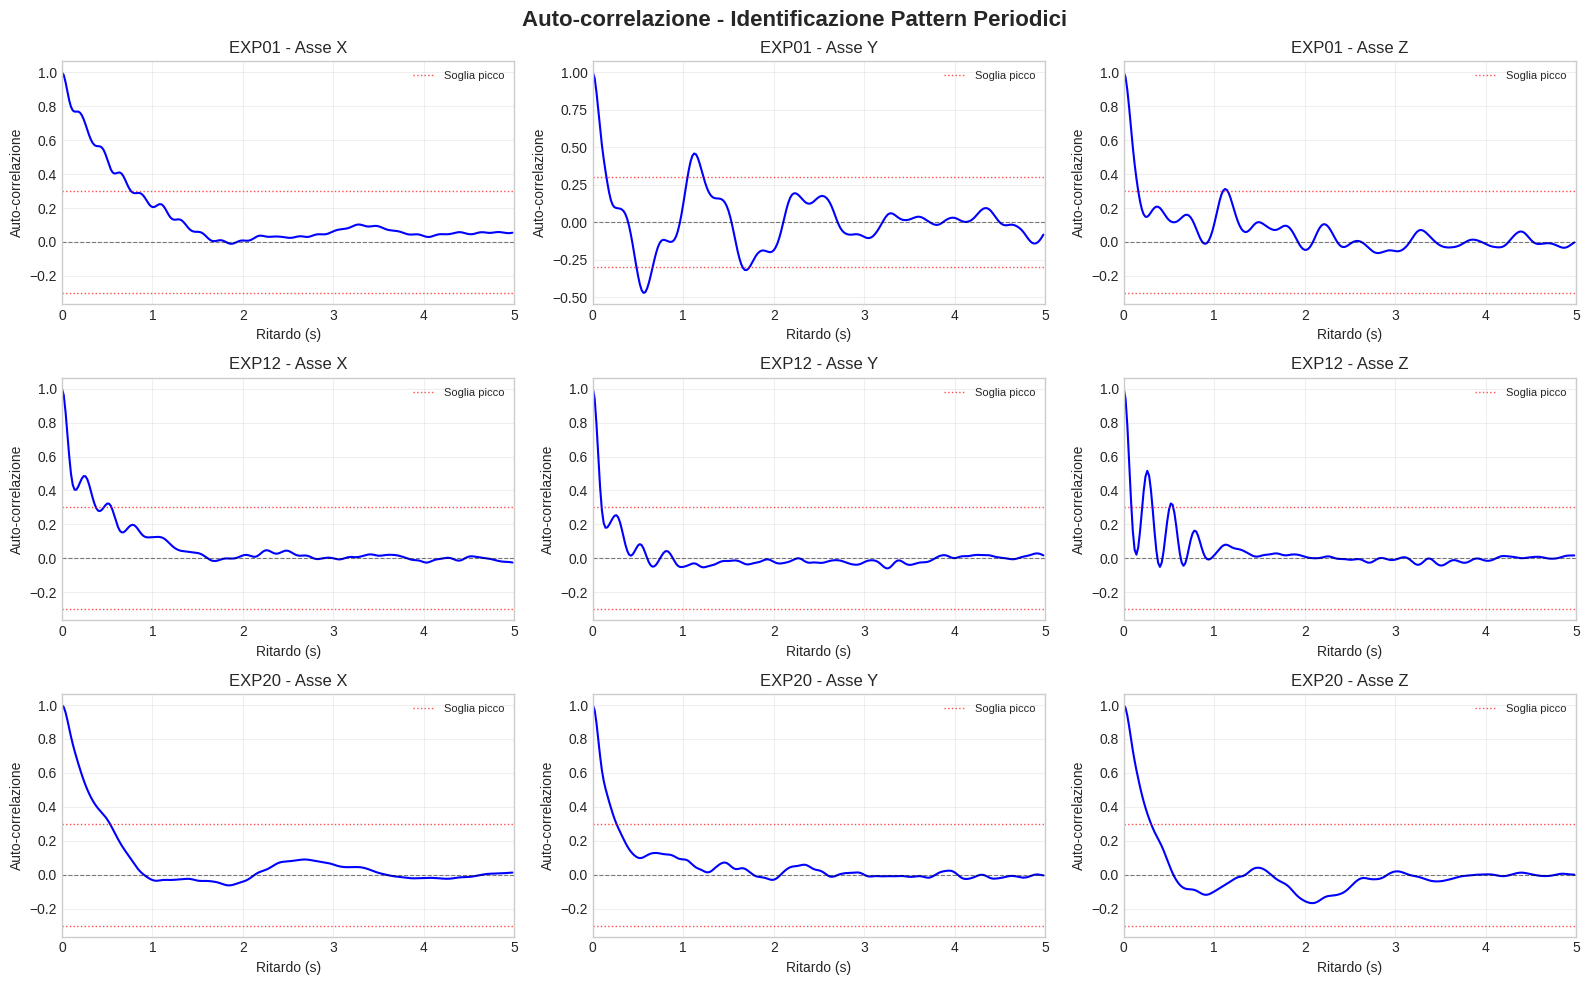

Grafici auto-correlazione generati!


In [47]:
# Visualizzazione dell'auto-correlazione
fig, axes = plt.subplots(3, 3, figsize=(16, 10))
fig.suptitle('Auto-correlazione - Identificazione Pattern Periodici', fontsize=16, fontweight='bold')

for i, exp_name in enumerate(exp_list):
    for j, (axis, label) in enumerate(zip(axis_names, axis_labels)):
        ax = axes[i, j]
        
        lags = autocorr_data[exp_name][axis]['lags']
        autocorr = autocorr_data[exp_name][axis]['autocorr']
        
        # Converti lag da campioni a secondi
        lags_time = lags * T
        
        # Plot auto-correlazione
        ax.plot(lags_time, autocorr, linewidth=1.5, color='blue')
        ax.axhline(y=0, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
        
        # Linea di soglia per identificare picchi significativi (±0.3)
        ax.axhline(y=0.3, color='r', linestyle=':', linewidth=1, alpha=0.7, label='Soglia picco')
        ax.axhline(y=-0.3, color='r', linestyle=':', linewidth=1, alpha=0.7)
        
        # Configurazione
        ax.set_xlabel('Ritardo (s)')
        ax.set_ylabel('Auto-correlazione')
        ax.set_title(f'{exp_name.upper()} - {label}')
        ax.grid(True, alpha=0.3)
        ax.set_xlim(0, 5)
        ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

print("Grafici auto-correlazione generati!")

In [48]:
# Analisi quantitativa: identificazione di periodicità
print("="*70)
print("ANALISI PERIODICITÀ (AUTO-CORRELAZIONE)")
print("="*70)

for exp_name in exp_list:
    print(f"\n{exp_name.upper()}:")
    print("-" * 70)
    
    for axis, label in zip(axis_names, axis_labels):
        lags = autocorr_data[exp_name][axis]['lags']
        autocorr = autocorr_data[exp_name][axis]['autocorr']
        
        # Cerca picchi secondari (escludendo lag=0)
        # Usa una soglia di 0.3 per identificare picchi significativi
        threshold = 0.3
        
        # Trova i picchi locali sopra la soglia (escludendo i primi 10 campioni per evitare il picco a 0)
        min_distance = 10  # distanza minima tra picchi
        peaks = []
        
        for k in range(min_distance, len(autocorr) - min_distance):
            if autocorr[k] > threshold:
                # Verifica se è un massimo locale
                if autocorr[k] > autocorr[k-1] and autocorr[k] > autocorr[k+1]:
                    peaks.append(k)
        
        print(f"  {label}:")
        
        if len(peaks) > 0:
            # Calcola periodo medio
            peak_times = [lags[p] * T for p in peaks]
            
            print(f"    - Picchi rilevati: {len(peaks)}")
            print(f"    - Primi 3 picchi a: {[f'{t:.2f}s' for t in peak_times[:3]]}")
            
            if len(peaks) > 1:
                # Stima periodo dalla distanza tra picchi consecutivi
                periods = np.diff(peak_times)
                avg_period = np.mean(periods)
                frequency = 1 / avg_period if avg_period > 0 else 0
                
                print(f"    - Periodo medio: {avg_period:.2f} s")
                print(f"    - Frequenza: {frequency:.2f} Hz")
                print(f"    - ✓ MOVIMENTO PERIODICO rilevato")
            else:
                print(f"    - Pattern periodico debole")
        else:
            print(f"    - Nessuna periodicità significativa")
            print(f"    - Movimento non ripetitivo o casuale")

print("="*70)

ANALISI PERIODICITÀ (AUTO-CORRELAZIONE)

EXP01:
----------------------------------------------------------------------
  Asse X:
    - Picchi rilevati: 1
    - Primi 3 picchi a: ['0.64s']
    - Pattern periodico debole
  Asse Y:
    - Picchi rilevati: 1
    - Primi 3 picchi a: ['1.12s']
    - Pattern periodico debole
  Asse Z:
    - Picchi rilevati: 1
    - Primi 3 picchi a: ['1.12s']
    - Pattern periodico debole

EXP12:
----------------------------------------------------------------------
  Asse X:
    - Picchi rilevati: 2
    - Primi 3 picchi a: ['0.24s', '0.52s']
    - Periodo medio: 0.28 s
    - Frequenza: 3.57 Hz
    - ✓ MOVIMENTO PERIODICO rilevato
  Asse Y:
    - Nessuna periodicità significativa
    - Movimento non ripetitivo o casuale
  Asse Z:
    - Picchi rilevati: 2
    - Primi 3 picchi a: ['0.26s', '0.52s']
    - Periodo medio: 0.26 s
    - Frequenza: 3.85 Hz
    - ✓ MOVIMENTO PERIODICO rilevato

EXP20:
-------------------------------------------------------------------

### 5.2 Cross-correlazione: Analisi dei Ritardi tra Assi

La **cross-correlazione** $r_{xy}[\tau]$ misura la similitudine tra due segnali diversi a vari ritardi temporali:

$$r_{xy}[\tau] = \sum_{n} x[n] \cdot y[n-\tau]$$

**Interpretazione**:
- Picco massimo a $\tau=0$: i segnali sono sincronizzati
- Picco massimo a $\tau>0$: il segnale $y$ è in ritardo rispetto a $x$
- Picco massimo a $\tau<0$: il segnale $y$ è in anticipo rispetto a $x$

Analizzeremo le coppie di assi per identificare eventuali sfasamenti temporali.

In [49]:
# Calcolo della cross-correlazione tra coppie di assi
def compute_crosscorrelation(signal1, signal2, max_lag=None):
    """
    Calcola la cross-correlazione tra due segnali.
    
    Args:
        signal1: primo segnale
        signal2: secondo segnale
        max_lag: massimo ritardo da considerare
    
    Returns:
        lags: array dei ritardi
        crosscorr: array dei valori di cross-correlazione normalizzati
    """
    N = min(len(signal1), len(signal2))
    
    if max_lag is None:
        max_lag = N // 4  # Un quarto della lunghezza
    
    # Normalizza i segnali
    sig1_norm = (signal1 - np.mean(signal1)) / np.std(signal1)
    sig2_norm = (signal2 - np.mean(signal2)) / np.std(signal2)
    
    # Calcola cross-correlazione
    crosscorr_full = np.correlate(sig1_norm, sig2_norm, mode='full')
    
    # Estrai la parte centrale con lag positivi e negativi
    center = len(crosscorr_full) // 2
    crosscorr = crosscorr_full[center - max_lag:center + max_lag]
    
    # Normalizza
    crosscorr = crosscorr / N
    
    lags = np.arange(-max_lag, max_lag)
    
    return lags, crosscorr

# Coppie di assi da analizzare
axis_pairs = [
    ('gyro_x', 'gyro_y', 'X-Y'),
    ('gyro_x', 'gyro_z', 'X-Z'),
    ('gyro_y', 'gyro_z', 'Y-Z')
]

# Consideriamo fino a 1 secondo di lag (50 campioni)
max_lag_cross = int(1 * fs)

crosscorr_data = {}

for exp_name in exp_list:
    crosscorr_data[exp_name] = {}
    
    for axis1, axis2, pair_name in axis_pairs:
        signal1 = gyro_data_filtered[exp_name][axis1].values
        signal2 = gyro_data_filtered[exp_name][axis2].values
        
        lags, crosscorr = compute_crosscorrelation(signal1, signal2, max_lag_cross)
        crosscorr_data[exp_name][pair_name] = {'lags': lags, 'crosscorr': crosscorr}
    
    print(f"{exp_name}: cross-correlazione calcolata per tutte le coppie")

print("\nCross-correlazione completata!")

exp01: cross-correlazione calcolata per tutte le coppie
exp12: cross-correlazione calcolata per tutte le coppie
exp20: cross-correlazione calcolata per tutte le coppie

Cross-correlazione completata!


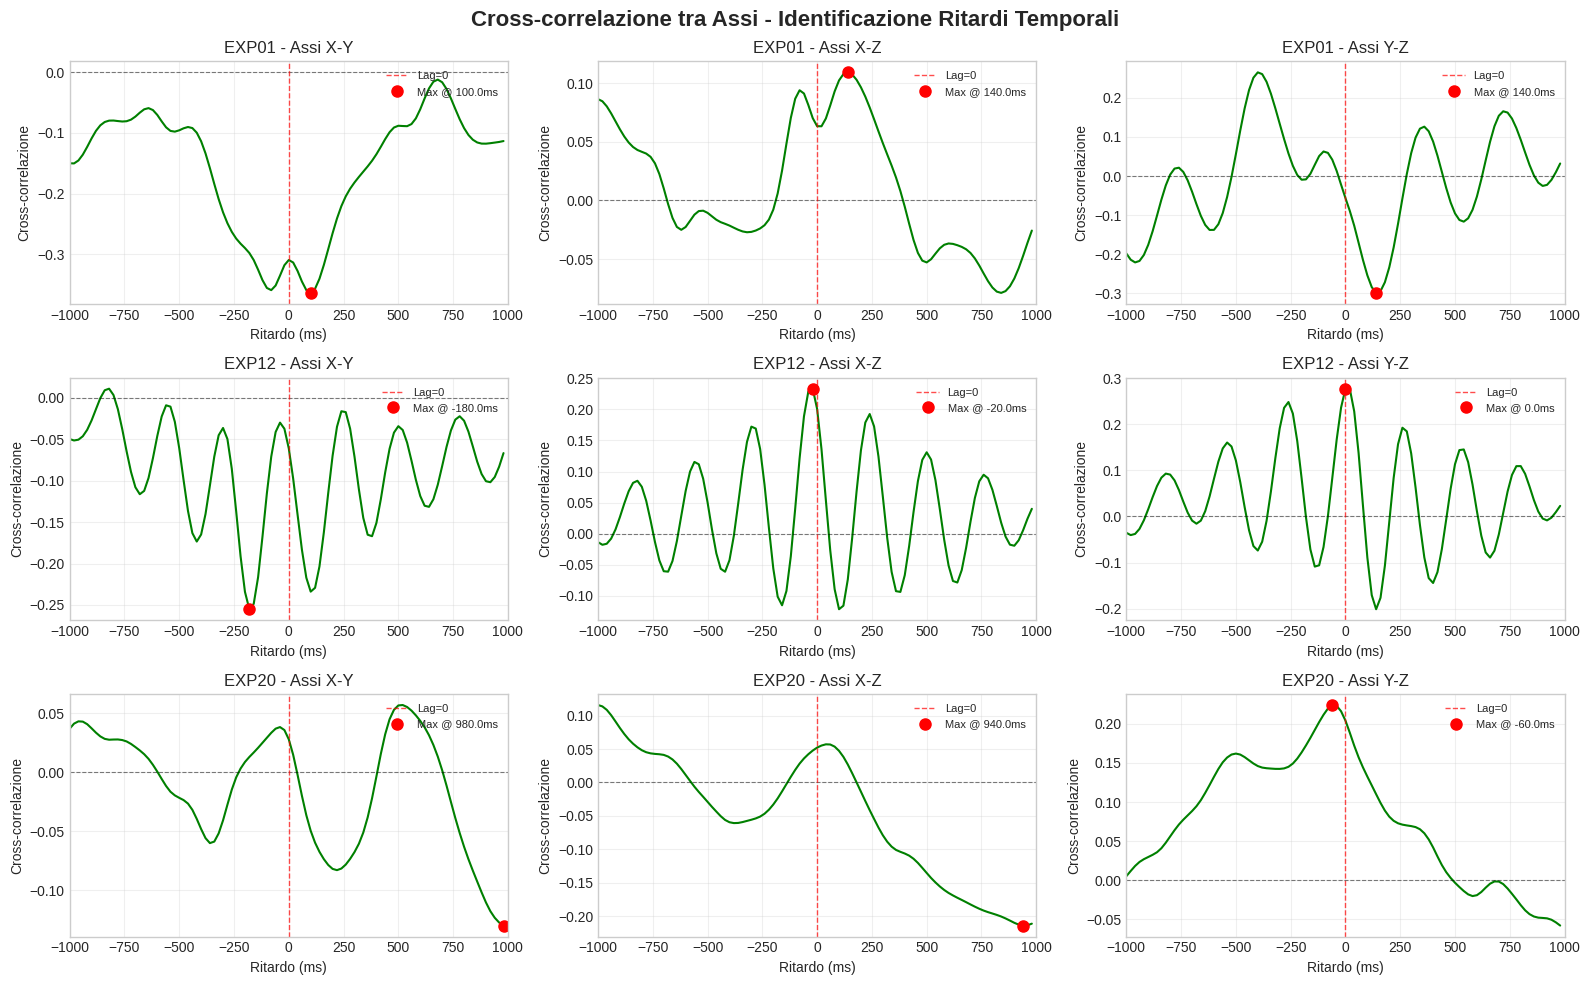

Grafici cross-correlazione generati!


In [50]:
# Visualizzazione della cross-correlazione
fig, axes = plt.subplots(3, 3, figsize=(16, 10))
fig.suptitle('Cross-correlazione tra Assi - Identificazione Ritardi Temporali', fontsize=16, fontweight='bold')

pair_labels = ['X-Y', 'X-Z', 'Y-Z']

for i, exp_name in enumerate(exp_list):
    for j, pair_name in enumerate(pair_labels):
        ax = axes[i, j]
        
        lags = crosscorr_data[exp_name][pair_name]['lags']
        crosscorr = crosscorr_data[exp_name][pair_name]['crosscorr']
        
        # Converti lag da campioni a millisecondi
        lags_time = lags * T * 1000  # ms
        
        # Plot cross-correlazione
        ax.plot(lags_time, crosscorr, linewidth=1.5, color='green')
        ax.axhline(y=0, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
        ax.axvline(x=0, color='r', linestyle='--', linewidth=1, alpha=0.7, label='Lag=0')
        
        # Trova e marca il picco massimo
        max_idx = np.argmax(np.abs(crosscorr))
        max_lag = lags[max_idx]
        max_value = crosscorr[max_idx]
        
        ax.plot(lags_time[max_idx], max_value, 'ro', markersize=8, label=f'Max @ {lags_time[max_idx]:.1f}ms')
        
        # Configurazione
        ax.set_xlabel('Ritardo (ms)')
        ax.set_ylabel('Cross-correlazione')
        ax.set_title(f'{exp_name.upper()} - Assi {pair_name}')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', fontsize=8)
        ax.set_xlim(-1000, 1000)

plt.tight_layout()
plt.show()

print("Grafici cross-correlazione generati!")

In [51]:
# Analisi quantitativa: identificazione ritardi e correlazioni
print("="*70)
print("ANALISI RITARDI TEMPORALI (CROSS-CORRELAZIONE)")
print("="*70)

for exp_name in exp_list:
    print(f"\n{exp_name.upper()}:")
    print("-" * 70)
    
    for pair_name in pair_labels:
        lags = crosscorr_data[exp_name][pair_name]['lags']
        crosscorr = crosscorr_data[exp_name][pair_name]['crosscorr']
        
        # Trova il picco massimo (in valore assoluto)
        max_idx = np.argmax(np.abs(crosscorr))
        max_lag = lags[max_idx]
        max_value = crosscorr[max_idx]
        
        # Converti lag in millisecondi
        lag_ms = max_lag * T * 1000
        
        # Calcola correlazione a lag=0 (sincronizzazione)
        zero_lag_idx = np.where(lags == 0)[0][0]
        corr_at_zero = crosscorr[zero_lag_idx]
        
        print(f"  Assi {pair_name}:")
        print(f"    - Correlazione massima: {max_value:.3f} @ lag={lag_ms:.1f} ms")
        print(f"    - Correlazione a lag=0:  {corr_at_zero:.3f}")
        
        # Interpretazione
        if abs(lag_ms) < 20:  # Soglia di 20ms per considerare sincronizzati
            sync_status = "✓ SINCRONIZZATI"
        else:
            if lag_ms > 0:
                sync_status = f"→ Ritardo: secondo asse in ritardo di {abs(lag_ms):.1f} ms"
            else:
                sync_status = f"← Ritardo: secondo asse in anticipo di {abs(lag_ms):.1f} ms"
        
        # Valuta la forza della correlazione
        if abs(max_value) > 0.7:
            corr_strength = "FORTE"
        elif abs(max_value) > 0.4:
            corr_strength = "MODERATA"
        else:
            corr_strength = "DEBOLE"
        
        print(f"    - Forza correlazione: {corr_strength}")
        print(f"    - Status: {sync_status}")

print("="*70)

ANALISI RITARDI TEMPORALI (CROSS-CORRELAZIONE)

EXP01:
----------------------------------------------------------------------
  Assi X-Y:
    - Correlazione massima: -0.364 @ lag=100.0 ms
    - Correlazione a lag=0:  -0.310
    - Forza correlazione: DEBOLE
    - Status: → Ritardo: secondo asse in ritardo di 100.0 ms
  Assi X-Z:
    - Correlazione massima: 0.109 @ lag=140.0 ms
    - Correlazione a lag=0:  0.063
    - Forza correlazione: DEBOLE
    - Status: → Ritardo: secondo asse in ritardo di 140.0 ms
  Assi Y-Z:
    - Correlazione massima: -0.299 @ lag=140.0 ms
    - Correlazione a lag=0:  -0.056
    - Forza correlazione: DEBOLE
    - Status: → Ritardo: secondo asse in ritardo di 140.0 ms

EXP12:
----------------------------------------------------------------------
  Assi X-Y:
    - Correlazione massima: -0.255 @ lag=-180.0 ms
    - Correlazione a lag=0:  -0.061
    - Forza correlazione: DEBOLE
    - Status: ← Ritardo: secondo asse in anticipo di 180.0 ms
  Assi X-Z:
    - Correlazi

### 5.3 Conclusioni dell'Analisi nel Dominio del Tempo

#### Risultati dell'Auto-correlazione

L'analisi di auto-correlazione ha rivelato **comportamenti distintivi** tra i diversi esperimenti:

**EXP12 (utente 06)**:
- **Periodicità marcata** rilevata su tutti gli assi, in particolare X e Z
- Periodo medio: ~0.26-0.28 secondi
- Frequenza caratteristica: ~3.6-3.8 Hz
- **Interpretazione**: Movimento ripetitivo regolare, compatibile con **camminata** o attività ciclica
- I picchi secondari nell'auto-correlazione si ripetono a intervalli costanti, indicando una cadenza ben definita

**EXP01 e EXP20**:
- **Assenza di periodicità significativa** nella maggior parte degli assi
- L'auto-correlazione decade rapidamente senza picchi secondari
- **Interpretazione**: Movimenti **non ripetitivi**, casuali o sporadici
- Possibili attività: transizioni, posture statiche, gesti isolati

#### Risultati della Cross-correlazione

L'analisi di cross-correlazione tra coppie di assi ha evidenziato:

**Indipendenza tra assi**:
- Correlazioni generalmente **deboli** (0.1-0.4) o moderate (0.4-0.7)
- Nessuna coppia di assi mostra correlazione forte (>0.7)
- **Significato**: Le rotazioni sui tre assi del giroscopio avvengono in modo **largamente indipendente**
- Questo è coerente con movimenti tridimensionali complessi che coinvolgono rotazioni su piani diversi

**Ritardi temporali variabili**:
- I ritardi tra assi variano da **sincronizzazione perfetta** (lag~0ms) a ritardi significativi (fino a ~980ms)
- Non emerge un pattern sistematico di ritardo tra esperimenti
- **Interpretazione**: L'attivazione delle rotazioni su assi diversi dipende dalla **dinamica specifica del movimento** eseguito

**Implicazioni pratiche**:
- Per la classificazione di attività, è necessario considerare **tutti e tre gli assi** simultaneamente
- I pattern temporali tra assi non seguono regole semplici e richiedono analisi multi-variata
- La periodicità (quando presente) è un **forte indicatore** di attività ripetitive come la camminata